# Graphes A et B — MIMIC-IV + SNOMED CT (Athena)

Graphe A : patients reliés à leurs codes ICD et médicaments.  
Graphe B : graphe A + mapping ICD → SNOMED + hiérarchie is-a.  
Lance les cellules dans l'ordre.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Chemins et vérification des fichiers

In [ ]:
import os
import pandas as pd

BASE   = "/content/drive/MyDrive/Youssef/StageLirmm"
MIMIC  = BASE + "/hosp"
ATHENA = BASE + "/vocabulary_download_v5_{fa4cccb1-e82c-4ae5-bc68-563863e183ee}_1791532254461"
OUT    = BASE + "/graphs_out"

print("MIMIC-IV :")
for name in ["patients", "admissions", "diagnoses_icd", "d_icd_diagnoses", "prescriptions"]:
    ok = any(os.path.exists(f"{MIMIC}/{name}{ext}") for ext in (".csv.gz", ".csv"))
    print(("  OK        " if ok else "  MANQUANT  ") + name)

print("\nAthena :", sorted(os.listdir(ATHENA)))
voc = pd.read_csv(f"{ATHENA}/VOCABULARY.csv", sep="\t", quoting=3, dtype=str)
print("Vocabulaires téléchargés :", voc["vocabulary_id"].tolist())
manque = {"SNOMED", "ICD10CM", "ICD9CM"} - set(voc["vocabulary_id"])
print("Il manque :", manque if manque else "rien, tout est là")

MIMIC-IV :
  OK        patients
  OK        admissions
  OK        diagnoses_icd
  OK        d_icd_diagnoses
  MANQUANT  prescriptions

Athena : ['CONCEPT.csv', 'CONCEPT_ANCESTOR.csv', 'CONCEPT_CLASS.csv', 'CONCEPT_METADATA.csv', 'CONCEPT_RELATIONSHIP.csv', 'CONCEPT_RELATIONSHIP_METADATA.csv', 'CONCEPT_SYNONYM.csv', 'DOMAIN.csv', 'DRUG_STRENGTH.csv', 'PACK_CONTENT.csv', 'RELATIONSHIP.csv', 'VOCABULARY.csv']
Vocabulaires téléchargés : ['Vocabulary', 'ICD10CM', 'RxNorm', 'Relationship', 'Visit Type', 'Drug Type', 'Plan', 'Procedure Type', 'ICD9CM', 'LOINC', 'Episode', 'US Census', 'Metadata', 'Observation Type', 'Condition Type', 'Meas Type', 'Condition Status', nan, 'Obs Period Type', 'Visit', 'Cost Type', 'Sponsor', 'Plan Stop Reason', 'Device Type', 'SOPT', 'UB04 Typ bill', 'Cohort Type', 'ATC', 'Death Type', 'Note Type', 'Cost', 'OSM', 'UB04 Point of Origin', 'UB04 Pt dis status', 'Korean Revenue Code', 'UB04 Pri Typ of Adm', 'RxNorm Extension', 'Domain', 'Type Concept', 'Language', 

## 2. Écriture des scripts

In [ ]:
%%writefile /content/build_graphs.py
"""
Construction des graphes A (sans ontologie) et B (avec SNOMED CT) à partir de MIMIC-IV.

Graphe A : patients reliés à leurs codes de diagnostic (ICD-9 / ICD-10) et à leurs médicaments.
Graphe B : graphe A + mapping ICD -> SNOMED CT + toutes les relations sémantiques SNOMED :
           hiérarchie is-a et relations d'attributs (site anatomique, morphologie, agent causal...).
           A est inclus dans B : la seule différence est l'ontologie (ablation propre).
           --snomed-relations isa donne la variante hiérarchie seule.

Cible : polyarthrite rhumatoïde (PR). Le lien patient -> PR n'est PAS une arête du graphe,
il est stocké à part dans labels.csv (sinon fuite de données dans le message passing).

Coupure temporelle :
  - cas     : on ne garde que les séjours STRICTEMENT antérieurs au premier séjour avec un code PR ;
  - témoins : patients sans aucun code PR, on garde tous les séjours sauf le dernier.
  Les deux groupes doivent donc avoir au moins 2 séjours (structure symétrique).

Entrées attendues
  MIMIC-IV (module hosp) : patients, admissions, diagnoses_icd, d_icd_diagnoses, prescriptions
                           (.csv ou .csv.gz, dans <mimic-dir>/hosp/ ou directement dans <mimic-dir>/)
  SNOMED CT, deux formats possibles :
    a) Téléchargement Athena / OMOP (--athena-dir) : CONCEPT.csv + CONCEPT_RELATIONSHIP.csv.
       Contient à la fois la hiérarchie SNOMED ("Is a") et le mapping ICD -> SNOMED ("Maps to"),
       à condition d'avoir coché SNOMED, ICD10CM et ICD9CM lors du téléchargement.
    b) SNOMED CT RF2 (Snapshot) : sct2_Relationship_Snapshot_*.txt et sct2_Description_Snapshot-en_*.txt,
       avec un mapping ICD -> SNOMED au choix :
         --umls-mrconso MRCONSO.RRF   (passage par les CUI UMLS, couvre ICD-9 et ICD-10)
         --icd-snomed-map map.csv      (colonnes icd_code, icd_version, snomed_id ; codes sans point)

Sorties (dans --out-dir)
  graph_A/nodes.csv, graph_A/edges.csv, graph_B/nodes.csv, graph_B/edges.csv
  patient_features.csv, labels.csv, stats.json
  optionnel : graph_X.graphml (--graphml, pour Gephi) et graph_X.pt (--pyg, HeteroData PyTorch Geometric)

Exemples
  python build_graphs.py --mimic-dir /data/mimic-iv/3.1/hosp \\
      --athena-dir /data/vocabulary_download_v5_xxx --out-dir graphs_out --graphml

  python build_graphs.py --mimic-dir /data/mimic-iv/3.1 \\
      --snomed-relationships SnomedCT/Snapshot/Terminology/sct2_Relationship_Snapshot_INT_20250101.txt \\
      --snomed-descriptions  SnomedCT/Snapshot/Terminology/sct2_Description_Snapshot-en_INT_20250101.txt \\
      --umls-mrconso /data/umls/META/MRCONSO.RRF \\
      --out-dir graphs_out --graphml --pyg
"""

import argparse
import json
import re
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------------------
# Définition de la PR -- à valider avec ton encadrant
# --------------------------------------------------------------------------------------
# ICD-10-CM : M05 (PR séropositive) et M06 hors M06.1 (maladie de Still de l'adulte)
#             et hors M06.4 (polyarthropathie inflammatoire, non spécifique).
PR_ICD10_PREFIXES = ("M05", "M060", "M062", "M063", "M068", "M069")
# ICD-9-CM : 714.0 (PR), 714.1 (syndrome de Felty), 714.2 (PR avec atteinte viscérale)
PR_ICD9_PREFIXES = ("7140", "7141", "7142")

PR_SNOMED_ID = "69896004"            # Rheumatoid arthritis (disorder)
QUALIFIER_ROOT = "362981000"         # Qualifier value : Increased, Abnormal, Period of life...
OUTCOME_NODE = "OUT:PR"

# Constantes SNOMED CT RF2
ISA_TYPE = "116680003"
INFERRED = "900000000000011006"
FSN_TYPE = "900000000000003001"
# Concepts trop génériques : ils relieraient tous les patients entre eux et noieraient le signal.
# La racine, "Disease", et les sommets des 19 grandes hiérarchies SNOMED (atteintes via les attributs).
STOP_CONCEPTS = {
    "138875005",  # SNOMED CT Concept (racine)
    "64572001",   # Disease
    "404684003",  # Clinical finding
    "123037004",  # Body structure
    "49755003",   # Morphologically abnormal structure
    "105590001",  # Substance
    "410607006",  # Organism
    "362981000",  # Qualifier value
    "363787002",  # Observable entity
    "71388002",   # Procedure
    "243796009",  # Situation with explicit context
    "272379006",  # Event
    "260787004",  # Physical object
    "373873005",  # Pharmaceutical / biologic product
    "48176007",   # Social context
    "370115009",  # Special concept
    "900000000000441003",  # SNOMED CT Model Component
    "78621006",   # Physical force
    "254291000",  # Staging and scales
    "308916002",  # Environment or geographical location
    "123038009",  # Specimen
    "419891008",  # Record artifact
}

# Relations Athena SNOMED -> SNOMED qui ne sont pas de la connaissance médicale (versionnage, mapping, métadonnées)
ATHENA_NON_SEMANTIC = {"Maps to", "Mapped from", "Maps to value", "Value mapped from", "Subsumes",
                       "Has Module", "Module of", "Has status", "Status of"}


def is_non_semantic(rel: str) -> bool:
    return (rel in ATHENA_NON_SEMANTIC or rel.startswith(("Concept ", "SNOMED "))
            or "replace" in rel.lower())


def rel_name(label: str) -> str:
    """'Has finding site' -> 'has_finding_site' ; 'Finding site' -> 'finding_site'."""
    return re.sub(r"[^0-9a-z]+", "_", label.lower()).strip("_")


# --------------------------------------------------------------------------------------
# Lecture MIMIC-IV
# --------------------------------------------------------------------------------------
def find_table(mimic_dir: Path, name: str) -> Path:
    for cand in (mimic_dir / "hosp" / f"{name}.csv.gz", mimic_dir / "hosp" / f"{name}.csv",
                 mimic_dir / f"{name}.csv.gz", mimic_dir / f"{name}.csv"):
        if cand.exists():
            return cand
    raise FileNotFoundError(f"Table MIMIC-IV introuvable : {name} (cherchée dans {mimic_dir})")


def is_pr(codes: pd.Series, versions: pd.Series) -> pd.Series:
    codes = codes.astype(str)
    m10 = (versions == 10) & codes.str.startswith(PR_ICD10_PREFIXES)
    m9 = (versions == 9) & codes.str.startswith(PR_ICD9_PREFIXES)
    return m10 | m9


def load_core_tables(mimic_dir: Path):
    adm = pd.read_csv(find_table(mimic_dir, "admissions"),
                      usecols=["subject_id", "hadm_id", "admittime"], parse_dates=["admittime"])
    dx = pd.read_csv(find_table(mimic_dir, "diagnoses_icd"),
                     usecols=["subject_id", "hadm_id", "icd_code", "icd_version"],
                     dtype={"icd_code": str})
    dx["icd_code"] = dx["icd_code"].str.strip().str.upper()
    pat = pd.read_csv(find_table(mimic_dir, "patients"),
                      usecols=["subject_id", "gender", "anchor_age", "anchor_year"])
    d_icd = pd.read_csv(find_table(mimic_dir, "d_icd_diagnoses"), dtype={"icd_code": str})
    d_icd["icd_code"] = d_icd["icd_code"].str.strip().str.upper()
    return adm, dx, pat, d_icd


def build_cohort(adm, dx, controls_per_case, seed, max_cases=None):
    """Retourne (cohort, feat_adm) : cohorte avec date index et y, et séjours utilisables comme features."""
    adm = adm.sort_values(["subject_id", "admittime"])
    dx_t = dx.merge(adm[["hadm_id", "admittime"]], on="hadm_id", how="inner")
    pr_rows = dx_t[is_pr(dx_t["icd_code"], dx_t["icd_version"])]
    pr_subjects = set(pr_rows["subject_id"])

    first_adm = adm.groupby("subject_id")["admittime"].min()
    last_adm = adm.groupby("subject_id")["admittime"].max()
    n_adm = adm.groupby("subject_id").size()

    # Cas : date index = premier séjour avec un code PR ; il faut au moins un séjour avant
    case_index = pr_rows.groupby("subject_id")["admittime"].min()
    case_index = case_index[first_adm.loc[case_index.index] < case_index]
    if max_cases is not None and len(case_index) > max_cases:
        case_index = case_index.sample(max_cases, random_state=seed)

    # Témoins : jamais de code PR, >= 2 séjours ; date index = dernier séjour
    eligible = n_adm[n_adm >= 2].index.difference(pd.Index(sorted(pr_subjects)))
    eligible = eligible[first_adm.loc[eligible].values < last_adm.loc[eligible].values]
    n_ctrl = min(len(eligible), controls_per_case * len(case_index))
    rng = np.random.default_rng(seed)
    ctrl_ids = rng.choice(np.asarray(eligible), size=n_ctrl, replace=False)

    cohort = pd.concat([
        pd.DataFrame({"subject_id": case_index.index, "index_time": case_index.values, "y": 1}),
        pd.DataFrame({"subject_id": ctrl_ids, "index_time": last_adm.loc[ctrl_ids].values, "y": 0}),
    ], ignore_index=True)

    feat_adm = adm.merge(cohort[["subject_id", "index_time"]], on="subject_id", how="inner")
    feat_adm = feat_adm[feat_adm["admittime"] < feat_adm["index_time"]][["subject_id", "hadm_id"]]
    cohort = cohort[cohort["subject_id"].isin(feat_adm["subject_id"])].reset_index(drop=True)
    return cohort, feat_adm


def load_prescriptions(mimic_dir: Path, hadm_ids: set, chunksize=2_000_000):
    path = find_table(mimic_dir, "prescriptions")
    parts = []
    for chunk in pd.read_csv(path, usecols=["subject_id", "hadm_id", "drug"],
                             dtype={"drug": str}, chunksize=chunksize):
        chunk = chunk[chunk["hadm_id"].isin(hadm_ids)].dropna(subset=["drug"])
        if len(chunk):
            parts.append(chunk)
    if not parts:
        return pd.DataFrame(columns=["subject_id", "hadm_id", "drug"])
    rx = pd.concat(parts, ignore_index=True)
    rx["drug"] = (rx["drug"].str.lower().str.strip()
                  .str.replace(r"\s+", " ", regex=True))
    return rx[rx["drug"] != ""]


# --------------------------------------------------------------------------------------
# Graphe A
# --------------------------------------------------------------------------------------
def icd_node(code, version):
    return f"ICD{int(version)}:{code}"


def build_graph_a(cohort, feat_adm, dx, rx, pat, d_icd, min_patients):
    hadm_ids = set(feat_adm["hadm_id"])
    dx_f = dx[dx["hadm_id"].isin(hadm_ids)].copy()
    # Sécurité : aucun code PR en feature (normalement déjà exclu par la coupure temporelle)
    dx_f = dx_f[~is_pr(dx_f["icd_code"], dx_f["icd_version"])]
    dx_f["dst"] = [icd_node(c, v) for c, v in zip(dx_f["icd_code"], dx_f["icd_version"])]

    def patient_code_edges(df, relation):
        e = (df.groupby(["subject_id", "dst"])["hadm_id"].nunique()
             .rename("weight").reset_index())
        keep = e.groupby("dst")["subject_id"].nunique()
        keep = keep[keep >= min_patients].index
        e = e[e["dst"].isin(keep)]
        e["src"] = "P:" + e["subject_id"].astype(str)
        e["relation"] = relation
        return e[["src", "dst", "relation", "weight"]]

    edges = [patient_code_edges(dx_f, "has_diagnosis")]
    if rx is not None and len(rx):
        rx_f = rx[rx["hadm_id"].isin(hadm_ids)].copy()
        rx_f["dst"] = "DRUG:" + rx_f["drug"]
        edges.append(patient_code_edges(rx_f, "received_drug"))
    edges = pd.concat(edges, ignore_index=True)

    # Noeuds patients (on garde aussi les patients sans arête restante, pour ne pas biaiser la cohorte)
    p = cohort.merge(pat, on="subject_id", how="left")
    p["node_id"] = "P:" + p["subject_id"].astype(str)
    p["age"] = p["anchor_age"] + (pd.to_datetime(p["index_time"]).dt.year - p["anchor_year"])
    p["gender_male"] = (p["gender"] == "M").astype(int)
    patient_nodes = pd.DataFrame({"node_id": p["node_id"], "node_type": "patient",
                                  "label": "Patient " + p["subject_id"].astype(str)})

    icd_labels = {icd_node(c, v): t for c, v, t in
                  zip(d_icd["icd_code"], d_icd["icd_version"], d_icd["long_title"])}
    code_ids = edges.loc[edges["relation"] == "has_diagnosis", "dst"].unique()
    icd_nodes = pd.DataFrame({"node_id": code_ids, "node_type": "icd",
                              "label": [icd_labels.get(c, c) for c in code_ids]})
    drug_ids = edges.loc[edges["relation"] == "received_drug", "dst"].unique()
    drug_nodes = pd.DataFrame({"node_id": drug_ids, "node_type": "drug",
                               "label": [d.split(":", 1)[1] for d in drug_ids]})
    outcome = pd.DataFrame({"node_id": [OUTCOME_NODE], "node_type": ["outcome"],
                            "label": ["Polyarthrite rhumatoïde (cible)"]})

    nodes = pd.concat([patient_nodes, icd_nodes, drug_nodes, outcome], ignore_index=True)
    pfeat = p[["node_id", "age", "gender_male"]].copy()
    labels = pd.DataFrame({"node_id": p["node_id"], "subject_id": p["subject_id"], "y": p["y"]})
    return nodes, edges, pfeat, labels


# --------------------------------------------------------------------------------------
# Mapping ICD -> SNOMED CT
# --------------------------------------------------------------------------------------
def mapping_from_umls(mrconso_path: Path, chunksize=2_000_000):
    """ICD-9-CM / ICD-10-CM -> SNOMED CT via les CUI partagés dans MRCONSO.RRF (many-to-many)."""
    keep_sabs = {"ICD10CM", "ICD9CM", "SNOMEDCT_US"}
    parts = []
    for chunk in pd.read_csv(mrconso_path, sep="|", header=None, usecols=[0, 1, 11, 13, 16],
                             names=["CUI", "LAT", "SAB", "CODE", "SUPPRESS"], dtype=str,
                             chunksize=chunksize, quoting=3, keep_default_na=False):
        chunk = chunk[(chunk["SAB"].isin(keep_sabs)) & (chunk["LAT"] == "ENG")
                      & (chunk["SUPPRESS"] != "O")]
        if len(chunk):
            parts.append(chunk[["CUI", "SAB", "CODE"]])
    m = pd.concat(parts, ignore_index=True).drop_duplicates()

    sct = m[m["SAB"] == "SNOMEDCT_US"][["CUI", "CODE"]].rename(columns={"CODE": "snomed_id"})
    icd = m[m["SAB"] != "SNOMEDCT_US"].copy()
    # ICD-9-CM dans UMLS contient aussi les actes (2 chiffres avant le point) : on ne garde que les diagnostics
    is_icd9 = icd["SAB"] == "ICD9CM"
    icd = icd[~is_icd9 | (icd["CODE"].str.split(".").str[0].str.len() == 3)]
    icd["icd_version"] = np.where(icd["SAB"] == "ICD10CM", 10, 9)
    icd["icd_code"] = icd["CODE"].str.replace(".", "", regex=False).str.upper()   # MIMIC : codes sans point
    out = icd.merge(sct, on="CUI")[["icd_code", "icd_version", "snomed_id"]]
    return out.drop_duplicates()


def load_mapping(args):
    if args.icd_snomed_map:
        m = pd.read_csv(args.icd_snomed_map, dtype={"icd_code": str, "snomed_id": str})
        m["icd_code"] = m["icd_code"].str.replace(".", "", regex=False).str.strip().str.upper()
        return m[["icd_code", "icd_version", "snomed_id"]].drop_duplicates()
    if args.umls_mrconso:
        return mapping_from_umls(Path(args.umls_mrconso))
    raise ValueError("Graphe B : fournis --umls-mrconso ou --icd-snomed-map")


# --------------------------------------------------------------------------------------
# SNOMED CT
# --------------------------------------------------------------------------------------
def load_snomed(rel_path: Path, desc_path: Path = None):
    """SNOMED RF2. Retourne parents (is-a), attrs (concept -> {(relation, cible)}) et noms."""
    names = {}
    if desc_path:
        desc = pd.read_csv(desc_path, sep="\t", dtype=str, quoting=3,
                           usecols=["active", "conceptId", "typeId", "term"])
        desc = desc[(desc["active"] == "1") & (desc["typeId"] == FSN_TYPE)]
        desc = desc.drop_duplicates("conceptId")
        tag = re.compile(r"\s*\([^()]*\)$")          # retire le tag sémantique, ex. " (disorder)"
        names = {c: tag.sub("", t) for c, t in zip(desc["conceptId"], desc["term"])}

    rel = pd.read_csv(rel_path, sep="\t", dtype=str, quoting=3,
                      usecols=["active", "sourceId", "destinationId", "typeId", "characteristicTypeId"])
    rel = rel[rel["active"] == "1"]
    if (rel["characteristicTypeId"] == INFERRED).any():
        rel = rel[rel["characteristicTypeId"] == INFERRED]
    parents, attrs = defaultdict(set), defaultdict(set)
    rname = {t: rel_name(names.get(t, t)) for t in rel["typeId"].unique()}
    for s, d, t in zip(rel["sourceId"], rel["destinationId"], rel["typeId"]):
        if t == ISA_TYPE:
            parents[s].add(d)
        else:
            attrs[s].add((rname[t], d))
    return parents, attrs, names


def find_athena_file(athena_dir: Path, name: str) -> Path:
    for cand in (athena_dir / f"{name}.csv", *athena_dir.glob(f"**/{name}.csv")):
        if cand.exists():
            return cand
    raise FileNotFoundError(f"{name}.csv introuvable dans {athena_dir}")


def load_athena(athena_dir: Path, chunksize=2_000_000):
    """Téléchargement Athena (OMOP) : hiérarchie SNOMED, noms des concepts et mapping ICD -> SNOMED.
    Les noeuds gardent leur code SNOMED (SCTID), comme avec RF2."""
    kw = dict(sep="\t", dtype=str, quoting=3, keep_default_na=False, chunksize=chunksize)
    parts = []
    for ch in pd.read_csv(find_athena_file(athena_dir, "CONCEPT"),
                          usecols=["concept_id", "concept_name", "vocabulary_id", "concept_code"], **kw):
        parts.append(ch[ch["vocabulary_id"].isin({"SNOMED", "ICD10CM", "ICD9CM"})])
    c = pd.concat(parts, ignore_index=True)
    counts = c["vocabulary_id"].value_counts().to_dict()
    print("  vocabulaires trouvés dans CONCEPT.csv :", counts)
    if not counts.get("SNOMED"):
        raise SystemExit("Aucun concept SNOMED dans CONCEPT.csv : vérifie le téléchargement Athena.")
    if not (counts.get("ICD10CM") or counts.get("ICD9CM")):
        raise SystemExit("Ni ICD10CM ni ICD9CM dans CONCEPT.csv : retélécharge depuis Athena en cochant "
                         "SNOMED, ICD10CM et ICD9CM (sinon pas de mapping ICD -> SNOMED).")

    sct = c[c["vocabulary_id"] == "SNOMED"]
    sct_code = dict(zip(sct["concept_id"], sct["concept_code"]))
    names = dict(zip(sct["concept_code"], sct["concept_name"]))
    icd = c[c["vocabulary_id"] != "SNOMED"]
    icd_code = dict(zip(icd["concept_id"], icd["concept_code"].str.replace(".", "", regex=False).str.upper()))
    icd_ver = dict(zip(icd["concept_id"], np.where(icd["vocabulary_id"] == "ICD10CM", 10, 9)))
    sct_ids, icd_ids = set(sct_code), set(icd_code)

    reverse = {}
    rel_file = list(athena_dir.glob("**/RELATIONSHIP.csv"))
    if rel_file:
        r = pd.read_csv(rel_file[0], sep="\t", dtype=str, quoting=3, keep_default_na=False,
                        usecols=["relationship_id", "reverse_relationship_id"])
        reverse = dict(zip(r["relationship_id"], r["reverse_relationship_id"]))

    isa_parts, att_parts, maps, semantic = [], [], [], {}
    for ch in pd.read_csv(find_athena_file(athena_dir, "CONCEPT_RELATIONSHIP"),
                          usecols=["concept_id_1", "concept_id_2", "relationship_id", "invalid_reason"], **kw):
        ch = ch[ch["invalid_reason"] == ""]
        ss = ch[ch["concept_id_1"].isin(sct_ids) & ch["concept_id_2"].isin(sct_ids)]
        for rel in ss["relationship_id"].unique():
            if rel not in semantic:
                semantic[rel] = rel != "Is a" and not is_non_semantic(rel)
        isa_parts.append(ss.loc[ss["relationship_id"] == "Is a", ["concept_id_1", "concept_id_2"]])
        att = ss[ss["relationship_id"].map(semantic)]
        att_parts.append(att[["concept_id_1", "concept_id_2", "relationship_id"]].astype(
            {"relationship_id": "category"}))
        mt = ch[(ch["relationship_id"] == "Maps to") & ch["concept_id_1"].isin(icd_ids) & ch["concept_id_2"].isin(sct_ids)]
        maps.append(mt[["concept_id_1", "concept_id_2"]])

    # Chaque relation existe dans les deux sens ("Has finding site" / "Finding site of") : on n'en garde qu'un.
    # Le bon sens va du concept défini vers sa valeur (maladie -> site, complication -> cause) : c'est le sens
    # "plusieurs vers un", où chaque source a peu de cibles. On le mesure sur les données plutôt que de se fier
    # aux noms, qui ne suivent pas toujours la même convention dans Athena.
    att = pd.concat(att_parts, ignore_index=True)
    att["relationship_id"] = att["relationship_id"].astype(str)
    st = att.groupby("relationship_id").agg(n=("concept_id_1", "size"), src=("concept_id_1", "nunique"))
    fan_out = (st["n"] / st["src"]).to_dict()
    keep, report = set(), []
    for rel in st.index:
        rev = reverse.get(rel)
        if rev is None and not reverse:                 # pas de RELATIONSHIP.csv : convention de nommage
            if rel.startswith("Has "):
                keep.add(rel)
            continue
        if rev is None or rev == rel or rev not in fan_out:
            keep.add(rel)                               # relation sans inverse dans les données
            continue
        a, b = fan_out[rel], fan_out[rev]
        tie = rel.startswith("Has ") or (not rev.startswith("Has ") and rel < rev)
        if a < b or (a == b and tie):
            keep.add(rel)
            report.append(f"{rel} (et non « {rev} »)")
    att = att[att["relationship_id"].isin(keep)]

    parents, attrs = defaultdict(set), defaultdict(set)
    isa = pd.concat(isa_parts, ignore_index=True)
    for a, b in zip(isa["concept_id_1"], isa["concept_id_2"]):
        parents[sct_code[a]].add(sct_code[b])
    for a, b, rel in zip(att["concept_id_1"], att["concept_id_2"], att["relationship_id"]):
        attrs[sct_code[a]].add((rel_name(rel), sct_code[b]))
    rel_counts = {"Is a": len(isa), **att["relationship_id"].value_counts().to_dict()}
    if report:
        print("  sens retenu pour les relations à double sens :", "; ".join(report))
    m = pd.concat(maps, ignore_index=True)
    mapping = pd.DataFrame({"icd_code": m["concept_id_1"].map(icd_code),
                            "icd_version": m["concept_id_1"].map(icd_ver).astype(int),
                            "snomed_id": m["concept_id_2"].map(sct_code)}).drop_duplicates()
    top = sorted(rel_counts.items(), key=lambda kv: -kv[1])
    print(f"  {len(mapping)} correspondances ICD -> SNOMED")
    print(f"  relations SNOMED gardées ({len(top)} types, dans toute l'ontologie) :",
          ", ".join(f"{k} ({v})" for k, v in top))
    return parents, attrs, names, mapping


def all_ancestors(concept, parents, memo):
    """Ensemble complet des ancêtres (sans limite de profondeur), mémoïsé."""
    if concept in memo:
        return memo[concept]
    seen, stack = set(), list(parents.get(concept, ()))
    while stack:
        c = stack.pop()
        if c in seen:
            continue
        seen.add(c)
        if c in memo:
            seen |= memo[c]
        else:
            stack.extend(parents.get(c, ()))
    memo[concept] = seen
    return seen


def bounded_closure(seeds, parents, hops, stops=STOP_CONCEPTS):
    """Ancêtres jusqu'à `hops` niveaux au-dessus des seeds, en s'arrêtant aux concepts trop génériques."""
    nodes, edges, frontier = set(seeds), set(), set(seeds)
    for _ in range(hops):
        nxt = set()
        for c in frontier:
            for p in parents.get(c, ()):
                if p in stops:
                    continue
                edges.add((c, p))
                if p not in nodes:
                    nxt.add(p)
        nodes |= nxt
        frontier = nxt
    return nodes, edges


def build_graph_b(nodes_a, edges_a, mapping, parents, attrs, names, hops, attr_hops,
                  with_attrs=True, extra_stops=(), keep_qualifiers=False):
    """Graphe A + concepts SNOMED : hiérarchie is-a (hops niveaux) et, si with_attrs, relations
    d'attributs (site anatomique, morphologie...) avec la hiérarchie de leurs cibles (attr_hops niveaux).
    Sauf keep_qualifiers, les attributs qui pointent vers une valeur qualificative ("Increased",
    "Abnormal", "Period of life"...) sont retirés : ces valeurs relient des maladies sans rapport."""
    stops = STOP_CONCEPTS | set(extra_stops)
    icd_ids = nodes_a.loc[nodes_a["node_type"] == "icd", "node_id"]
    m = mapping.copy()
    m["src"] = [icd_node(c, v) for c, v in zip(m["icd_code"], m["icd_version"])]
    m = m[m["src"].isin(set(icd_ids))]
    m = m[m["snomed_id"].isin(set(parents) | set(attrs) | set(names))]   # concepts de l'édition SNOMED

    # Anti-fuite : un code feature ne doit pointer ni vers la PR ou ses descendants, ni vers un concept
    # défini à partir de la PR par un attribut (ex. "anémie due à la PR")
    memo = {}
    def is_pr_like(s):
        return s == PR_SNOMED_ID or PR_SNOMED_ID in all_ancestors(s, parents, memo)
    def leaky(s):
        return is_pr_like(s) or (with_attrs and any(is_pr_like(t) for _, t in attrs.get(s, ())))
    bad = {s for s in m["snomed_id"].unique() if leaky(s)}
    n_leak = int(m["snomed_id"].isin(bad).sum())
    m = m[~m["snomed_id"].isin(bad)]

    seeds = set(m["snomed_id"]) | {PR_SNOMED_ID}
    sct_nodes, isa_edges = bounded_closure(seeds, parents, hops, stops)
    attr_edges, n_qualif = set(), 0
    if with_attrs:
        targets = set()
        for c in sct_nodes:
            for rel, t in attrs.get(c, ()):
                if t in stops:
                    continue
                if not keep_qualifiers and (t == QUALIFIER_ROOT or QUALIFIER_ROOT in all_ancestors(t, parents, memo)):
                    n_qualif += 1
                    continue
                attr_edges.add((c, rel, t))
                targets.add(t)
        t_nodes, t_isa = bounded_closure(targets, parents, attr_hops, stops)
        sct_nodes = sct_nodes | t_nodes
        isa_edges = isa_edges | t_isa

    sct = sorted(sct_nodes)
    snomed_nodes = pd.DataFrame({"node_id": ["SCT:" + s for s in sct], "node_type": "snomed",
                                 "label": [names.get(s, s) for s in sct]})
    maps_to = pd.DataFrame({"src": m["src"], "dst": "SCT:" + m["snomed_id"],
                            "relation": "maps_to", "weight": 1})
    isa = pd.DataFrame({"src": ["SCT:" + c for c, _ in isa_edges],
                        "dst": ["SCT:" + p for _, p in isa_edges], "relation": "is_a", "weight": 1})
    att = pd.DataFrame({"src": ["SCT:" + c for c, _, _ in attr_edges],
                        "dst": ["SCT:" + t for _, _, t in attr_edges],
                        "relation": [r for _, r, _ in attr_edges], "weight": 1})
    target = pd.DataFrame({"src": [OUTCOME_NODE], "dst": ["SCT:" + PR_SNOMED_ID],
                           "relation": "maps_to", "weight": [1]})

    nodes_b = pd.concat([nodes_a, snomed_nodes], ignore_index=True)
    edges_b = pd.concat([edges_a, maps_to, isa, att, target], ignore_index=True).drop_duplicates(
        subset=["src", "dst", "relation"])

    # Concepts les plus connectés : à surveiller, un "hub" trop générique relie tout le monde
    onto = edges_b[edges_b["dst"].str.startswith("SCT:") & (edges_b["relation"] != "maps_to")]
    hubs = onto["dst"].value_counts().head(10)
    label = dict(zip(snomed_nodes["node_id"], snomed_nodes["label"]))
    coverage = m["src"].nunique() / max(len(icd_ids), 1)
    return nodes_b, edges_b, {"icd_mapped_fraction": round(coverage, 3),
                              "leaky_mappings_removed": n_leak,
                              "qualifier_attributes_removed": n_qualif,
                              "top_snomed_hubs": [f"{n} {label.get(n, '')} ({k})" for n, k in hubs.items()]}


# --------------------------------------------------------------------------------------
# Exports
# --------------------------------------------------------------------------------------
def save_graph(nodes, edges, folder: Path):
    folder.mkdir(parents=True, exist_ok=True)
    nodes.to_csv(folder / "nodes.csv", index=False)
    edges.to_csv(folder / "edges.csv", index=False)


def graph_stats(nodes, edges):
    return {"nodes": nodes["node_type"].value_counts().to_dict(),
            "edges": edges["relation"].value_counts().to_dict()}


def export_graphml(nodes, edges, path: Path):
    import networkx as nx
    g = nx.MultiDiGraph()        # deux concepts peuvent être reliés par plusieurs relations
    for n, t, l in zip(nodes["node_id"], nodes["node_type"], nodes["label"]):
        g.add_node(n, node_type=t, label=str(l))
    for s, d, r, w in zip(edges["src"], edges["dst"], edges["relation"], edges["weight"]):
        g.add_edge(s, d, relation=r, weight=float(w))
    nx.write_graphml(g, path)


def export_pyg(nodes, edges, pfeat, labels, path: Path):
    import torch
    import torch_geometric.transforms as T
    from torch_geometric.data import HeteroData

    data = HeteroData()
    index = {}
    for ntype, g in nodes.groupby("node_type", sort=False):
        ids = g["node_id"].tolist()
        index[ntype] = {n: i for i, n in enumerate(ids)}
        data[ntype].num_nodes = len(ids)
        data[ntype].node_ids = ids

    pids = nodes.loc[nodes["node_type"] == "patient", "node_id"].tolist()
    pf = pfeat.set_index("node_id").loc[pids]
    age = pf["age"].astype(float).fillna(pf["age"].mean())
    age = (age - age.mean()) / (age.std() + 1e-8)
    data["patient"].x = torch.tensor(np.c_[age.values, pf["gender_male"].values], dtype=torch.float)
    data["patient"].y = torch.tensor(labels.set_index("node_id").loc[pids, "y"].values, dtype=torch.long)

    ntype_of = dict(zip(nodes["node_id"], nodes["node_type"]))
    e = edges.copy()
    e["st"], e["dt"] = e["src"].map(ntype_of), e["dst"].map(ntype_of)
    for (st, rel, dt), g in e.groupby(["st", "relation", "dt"]):
        src = [index[st][n] for n in g["src"]]
        dst = [index[dt][n] for n in g["dst"]]
        data[st, rel, dt].edge_index = torch.tensor([src, dst], dtype=torch.long)
        data[st, rel, dt].edge_weight = torch.tensor(g["weight"].values, dtype=torch.float)

    data = T.ToUndirected()(data)       # ajoute les arêtes inverses (rev_*) pour le message passing
    torch.save(data, path)
    return data


# --------------------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--mimic-dir", required=True, type=Path)
    ap.add_argument("--out-dir", default=Path("graphs_out"), type=Path)
    ap.add_argument("--athena-dir", type=Path, help="dossier d'un téléchargement Athena (CONCEPT.csv...)")
    ap.add_argument("--snomed-relationships", type=Path)
    ap.add_argument("--snomed-descriptions", type=Path)
    ap.add_argument("--umls-mrconso", type=Path)
    ap.add_argument("--icd-snomed-map", type=Path)
    ap.add_argument("--controls-per-case", type=int, default=5)
    ap.add_argument("--max-cases", type=int, default=None, help="limiter le nombre de cas (tests rapides)")
    ap.add_argument("--min-patients", type=int, default=5,
                    help="un code ou médicament doit concerner au moins N patients pour devenir un noeud")
    ap.add_argument("--snomed-hops", type=int, default=3,
                    help="niveaux d'ancêtres is-a gardés au-dessus des concepts mappés")
    ap.add_argument("--snomed-relations", choices=["all", "isa"], default="all",
                    help="all : is-a + relations d'attributs (défaut) ; isa : hiérarchie seule")
    ap.add_argument("--attr-hops", type=int, default=1,
                    help="niveaux d'ancêtres is-a gardés au-dessus des cibles d'attributs (sites, morphologies...)")
    ap.add_argument("--stop-concepts", nargs="*", default=[],
                    help="SCTID supplémentaires à exclure (concepts hubs trop génériques)")
    ap.add_argument("--keep-qualifiers", action="store_true",
                    help="garder les attributs vers des valeurs qualificatives (Increased, Abnormal...)")
    ap.add_argument("--no-drugs", action="store_true")
    ap.add_argument("--graphml", action="store_true")
    ap.add_argument("--pyg", action="store_true")
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()
    out = args.out_dir
    out.mkdir(parents=True, exist_ok=True)

    print("Lecture de MIMIC-IV...")
    adm, dx, pat, d_icd = load_core_tables(args.mimic_dir)
    cohort, feat_adm = build_cohort(adm, dx, args.controls_per_case, args.seed, args.max_cases)
    print(f"  cohorte : {int(cohort['y'].sum())} cas PR, {int((cohort['y'] == 0).sum())} témoins")

    rx = None
    if not args.no_drugs:
        print("Lecture des prescriptions (filtrées sur la cohorte)...")
        rx = load_prescriptions(args.mimic_dir, set(feat_adm["hadm_id"]))

    nodes_a, edges_a, pfeat, labels = build_graph_a(cohort, feat_adm, dx, rx, pat, d_icd, args.min_patients)
    save_graph(nodes_a, edges_a, out / "graph_A")
    pfeat.to_csv(out / "patient_features.csv", index=False)
    labels.to_csv(out / "labels.csv", index=False)
    stats = {"cohort": {"cases": int(cohort["y"].sum()), "controls": int((cohort["y"] == 0).sum())},
             "graph_A": graph_stats(nodes_a, edges_a)}
    print("Graphe A :", stats["graph_A"])

    graphs = {"A": (nodes_a, edges_a)}
    if args.athena_dir or args.snomed_relationships:
        print("Lecture de SNOMED CT et du mapping ICD -> SNOMED...")
        if args.athena_dir:
            parents, attrs, names, mapping = load_athena(args.athena_dir)
        else:
            parents, attrs, names = load_snomed(args.snomed_relationships, args.snomed_descriptions)
            mapping = load_mapping(args)
        nodes_b, edges_b, info = build_graph_b(nodes_a, edges_a, mapping, parents, attrs, names,
                                               args.snomed_hops, args.attr_hops,
                                               with_attrs=args.snomed_relations == "all",
                                               extra_stops=args.stop_concepts,
                                               keep_qualifiers=args.keep_qualifiers)
        save_graph(nodes_b, edges_b, out / "graph_B")
        stats["graph_B"] = graph_stats(nodes_b, edges_b) | info
        graphs["B"] = (nodes_b, edges_b)
        print("Graphe B :", {k: v for k, v in stats["graph_B"].items() if k != "top_snomed_hubs"})
        print("Concepts SNOMED les plus connectés (à surveiller) :")
        for h in info["top_snomed_hubs"]:
            print("   ", h)
    else:
        print("Pas de fichiers SNOMED fournis : seul le graphe A est construit.")

    if args.graphml:
        for name, (n, e) in graphs.items():
            export_graphml(n, e, out / f"graph_{name}.graphml")
    if args.pyg:
        try:
            for name, (n, e) in graphs.items():
                data = export_pyg(n, e, pfeat, labels, out / f"graph_{name}.pt")
                print(f"HeteroData {name} :", data.metadata()[1])
        except ImportError:
            print("torch / torch_geometric non installés : export PyG ignoré.")

    (out / "stats.json").write_text(json.dumps(stats, indent=2, ensure_ascii=False))
    print(f"Terminé. Fichiers dans {out.resolve()}")


if __name__ == "__main__":
    main()


Writing /content/build_graphs.py


In [ ]:
%%writefile /content/visualize_graphs.py
"""
Visualisation des graphes A et B côte à côte, sur un cas PR et un témoin.

Par défaut le script choisit :
  - un cas PR avec un nombre de diagnostics lisible ;
  - le témoin qui partage le plus de concepts SNOMED avec ce cas dans le graphe B
    (c'est là qu'on voit ce que l'ontologie ajoute : des chemins entre patients qui n'existent pas dans A).

Colonnes : patients | codes ICD, médicaments, cible PR | concepts SNOMED (niveau 1, 2, 3...).
Le lien patient -> PR (en pointillés rouges) est le label à prédire : il n'est pas dans le graphe.

Exemple
  python visualize_graphs.py --graphs-dir graphs_out --out graphes_A_B.png
  python visualize_graphs.py --graphs-dir graphs_out --case 10012345 --control 10067890
"""

import argparse
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

OUTCOME_NODE = "OUT:PR"

# Couleur + forme par type de noeud (la forme évite que l'identité repose sur la couleur seule)
STYLE = {
    "case":     dict(color="#eb6834", shape="s", size=900, name="Patient PR (cas)"),
    "control":  dict(color="#8f8e88", shape="s", size=900, name="Patient témoin"),
    "icd":      dict(color="#2a78d6", shape="o", size=260, name="Code ICD"),
    "drug":     dict(color="#1baf7a", shape="^", size=260, name="Médicament"),
    "snomed":   dict(color="#6250d6", shape="D", size=200, name="Concept SNOMED CT"),
    "outcome":  dict(color="#e34948", shape="*", size=700, name="Cible : PR"),
}
TEXT = "#0b0b0b"
TEXT_2 = "#52514e"
EDGE = "#c9c8c2"
ATTR_COLOR = "#d55181"     # relations d'attributs SNOMED (site anatomique, morphologie...)


def load(graphs_dir: Path, name: str):
    folder = graphs_dir / f"graph_{name}"
    if not folder.exists():
        return None, None
    nodes = pd.read_csv(folder / "nodes.csv", dtype=str)
    edges = pd.read_csv(folder / "edges.csv", dtype={"src": str, "dst": str, "relation": str})
    return nodes, edges


def adjacency(edges):
    out = defaultdict(list)
    for s, d, r in zip(edges["src"], edges["dst"], edges["relation"]):
        out[(s, r)].append(d)
    sct = edges["src"].str.startswith("SCT:") & edges["dst"].str.startswith("SCT:")
    out["__snomed_rels__"] = sorted(edges.loc[sct, "relation"].unique())   # is_a + attributs
    return out


def snomed_reach(start_nodes, adj, max_depth=99):
    """Concepts SNOMED atteints depuis des codes ICD via maps_to, puis via toutes les relations
    SNOMED (is-a et attributs), avec leur niveau."""
    rels = adj.get("__snomed_rels__", [])
    level = {}
    frontier = []
    for n in start_nodes:
        for s in adj.get((n, "maps_to"), []):
            if s not in level:
                level[s] = 1
                frontier.append(s)
    while frontier:
        nxt = []
        for c in frontier:
            if level[c] >= max_depth:
                continue
            for rel in rels:
                for p in adj.get((c, rel), []):
                    if p not in level:
                        level[p] = level[c] + 1
                        nxt.append(p)
        frontier = nxt
    return level


def neighbors(adj, node, relation):
    return adj.get((node, relation), [])


def pick_patients(labels, adj_a, adj_b, case, control, seed, max_codes, depth):
    rng = np.random.default_rng(seed)
    pid = lambda s: f"P:{s}"
    cases = labels.loc[labels["y"] == "1", "node_id"].tolist()
    controls = labels.loc[labels["y"] == "0", "node_id"].tolist()

    if case is None:
        n_dx = {p: len(neighbors(adj_a, p, "has_diagnosis")) for p in cases}
        good = [p for p, k in n_dx.items() if 3 <= k <= max_codes] or [p for p, k in n_dx.items() if k > 0]
        if not good:
            raise SystemExit("Aucun cas PR avec des diagnostics dans le graphe.")
        case_id = good[rng.integers(len(good))]
    else:
        case_id = pid(case)

    if control is not None:
        return case_id, pid(control)

    def concepts(p):
        codes = neighbors(adj_a, p, "has_diagnosis")
        return set(snomed_reach(codes, adj_b, depth)) if adj_b else set(codes)

    ref = concepts(case_id)
    ref_codes = set(neighbors(adj_a, case_id, "has_diagnosis"))
    best, best_score = None, (-1, -1)
    for c in controls:
        k = len(neighbors(adj_a, c, "has_diagnosis"))
        if k == 0 or k > max_codes:
            continue
        score = (len(ref & concepts(c)), -len(ref_codes & set(neighbors(adj_a, c, "has_diagnosis"))))
        if score > best_score:
            best, best_score = c, score
    if best is None:
        best = controls[rng.integers(len(controls))]
    return case_id, best


def select_items(adj_a, patients, relation, limit):
    """Pour chaque patient, garde au plus `limit` voisins, en privilégiant ceux partagés par les deux patients."""
    lists = [neighbors(adj_a, p, relation) for p in patients]
    shared = set(lists[0]).intersection(*map(set, lists[1:])) if len(lists) > 1 else set()
    chosen = []
    for lst in lists:
        ordered = [x for x in lst if x in shared] + [x for x in lst if x not in shared]
        chosen.extend(ordered[:limit])
    return list(dict.fromkeys(chosen))


def build_subgraph(patients, case_id, nodes, adj_a, adj_b, max_codes, max_drugs, depth=99, vue="complet"):
    ntype = dict(zip(nodes["node_id"], nodes["node_type"]))
    label = dict(zip(nodes["node_id"], nodes["label"]))
    g = nx.DiGraph()

    for p in patients:
        g.add_node(p, kind="case" if p == case_id else "control", layer=0)
    codes = select_items(adj_a, patients, "has_diagnosis", max_codes)
    drugs = select_items(adj_a, patients, "received_drug", max_drugs)
    for n in codes:
        g.add_node(n, kind="icd", layer=1)
    g.add_node(OUTCOME_NODE, kind="outcome", layer=1)
    for n in drugs:
        g.add_node(n, kind="drug", layer=1)

    for p in patients:
        for rel in ("has_diagnosis", "received_drug"):
            for d in neighbors(adj_a, p, rel):
                if d in g:
                    g.add_edge(p, d, relation=rel)

    if adj_b is not None:
        level = snomed_reach(codes + [OUTCOME_NODE], adj_b, depth)
        for s, lv in level.items():
            g.add_node(s, kind="snomed", layer=1 + lv)
        for n in codes + [OUTCOME_NODE]:
            for s in neighbors(adj_b, n, "maps_to"):
                g.add_edge(n, s, relation="maps_to")
        for s in level:
            for rel in adj_b["__snomed_rels__"]:
                for p in neighbors(adj_b, s, rel):
                    if p in g:
                        g.add_edge(s, p, relation=rel)
        if vue == "pr":
            # Seulement les concepts qui relient les codes des patients aux concepts atteints depuis la PR
            from_codes = set(snomed_reach(codes, adj_b, depth))
            from_pr = set(snomed_reach([OUTCOME_NODE], adj_b, depth))
            shared = from_codes & from_pr
            keep = set(shared)
            for s in shared:
                keep |= nx.ancestors(g, s)
            keep |= {s for s in from_pr if s in keep or s in neighbors(adj_b, OUTCOME_NODE, "maps_to")}
            g.remove_nodes_from([n for n, d in list(g.nodes(data=True)) if d["kind"] == "snomed" and n not in keep])
            g.graph["shared"] = len(shared)
        # Chaque concept est placé une colonne à droite de son prédécesseur le plus profond :
        # toutes les arêtes vont alors de gauche à droite, sans arête verticale qui traverse une colonne.
        sub = g.subgraph([n for n, d in g.nodes(data=True) if d["layer"] >= 1])
        if nx.is_directed_acyclic_graph(sub):
            for n in nx.topological_sort(sub):
                if g.nodes[n]["kind"] == "snomed":
                    preds = [g.nodes[p]["layer"] for p in sub.predecessors(n)]
                    if preds:
                        g.nodes[n]["layer"] = max(preds) + 1

    for n in g.nodes:
        txt = str(label.get(n, n))
        g.nodes[n]["text"] = txt if len(txt) <= 34 else txt[:32] + "…"
    return g


def layered_layout(g, dx=1.0):
    """Colonnes par couche ; dans chaque colonne, ordre par type puis par barycentre des voisins
    de gauche (heuristique de Sugiyama en une passe, pour limiter les croisements)."""
    layers = defaultdict(list)
    for n, d in g.nodes(data=True):
        layers[d["layer"]].append(n)
    step = 1.0 / max(max(len(v) for v in layers.values()) - 1, 1)
    rank = {"case": 0, "control": 1, "outcome": 0, "icd": 1, "drug": 2, "snomed": 1}
    pos = {}
    for L in sorted(layers):
        def bary(n):
            ys = [pos[p][1] for p in g.predecessors(n) if p in pos]
            return float(np.mean(ys)) if ys else 0.0
        order = sorted(layers[L], key=lambda n: (rank[g.nodes[n]["kind"]], -bary(n)))
        s = max(step, 0.12) if L == 0 else step          # les deux patients bien séparés
        top = s * (len(order) - 1) / 2
        for i, n in enumerate(order):
            pos[n] = (L * dx, top - i * s)
    return pos


def tallest_column(g):
    counts = defaultdict(int)
    for _, d in g.nodes(data=True):
        counts[d["layer"]] += 1
    return max(counts.values())


def draw(ax, g, case_id, title):
    pos = layered_layout(g)
    plain = [(u, v) for u, v, d in g.edges(data=True) if d["relation"] in ("has_diagnosis", "received_drug")]
    onto = [(u, v) for u, v, d in g.edges(data=True) if d["relation"] in ("maps_to", "is_a")]
    attr = [(u, v) for u, v, d in g.edges(data=True)
            if d["relation"] not in ("maps_to", "is_a", "has_diagnosis", "received_drug")]
    nx.draw_networkx_edges(g, pos, edgelist=plain, ax=ax, edge_color=EDGE, width=1.0, arrows=False)
    nx.draw_networkx_edges(g, pos, edgelist=onto, ax=ax, edge_color=STYLE["snomed"]["color"],
                           width=0.9, alpha=0.45, arrows=True, arrowsize=8, arrowstyle="-|>")
    nx.draw_networkx_edges(g, pos, edgelist=attr, ax=ax, edge_color=ATTR_COLOR, width=1.1, alpha=0.8,
                           style="dotted", arrows=True, arrowsize=8, arrowstyle="-|>")
    # Label à prédire : affiché, mais ce n'est PAS une arête du graphe
    if OUTCOME_NODE in g:
        nx.draw_networkx_edges(g, pos, edgelist=[(case_id, OUTCOME_NODE)], ax=ax, edge_color=STYLE["outcome"]["color"],
                               width=1.6, style="dashed", arrows=True, arrowsize=14, arrowstyle="-|>")

    for kind, st in STYLE.items():
        nl = [n for n, d in g.nodes(data=True) if d["kind"] == kind]
        if nl:
            nx.draw_networkx_nodes(g, pos, nodelist=nl, ax=ax, node_color=st["color"], node_shape=st["shape"],
                                   node_size=st["size"], edgecolors="white", linewidths=1.5)

    halo = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85)
    for n, (x, y) in pos.items():
        d = g.nodes[n]
        if d["kind"] in ("case", "control"):
            ax.text(x, y - 0.035, d["text"], ha="center", va="top", fontsize=8, color=TEXT, bbox=halo, zorder=3)
        else:
            ax.text(x + 0.06, y, d["text"], ha="left", va="center", fontsize=7, color=TEXT, bbox=halo, zorder=3)

    n_onto = sum(1 for _, d in g.nodes(data=True) if d["kind"] == "snomed")
    sub = f"{g.number_of_nodes()} noeuds, {g.number_of_edges()} arêtes" + (f" dont {n_onto} concepts SNOMED" if n_onto else "")
    if "shared" in g.graph:
        sub += f"\nvue « pr » : concepts reliant les codes des patients à la PR ({g.graph['shared']} points de rencontre)"
    ax.set_title(f"{title}\n{sub}", fontsize=11, color=TEXT)
    ax.axis("off")
    ax.margins(x=0.25, y=0.05)


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--graphs-dir", default=Path("graphs_out"), type=Path)
    ap.add_argument("--case", help="subject_id d'un cas PR (sinon choisi automatiquement)")
    ap.add_argument("--control", help="subject_id d'un témoin (sinon celui qui partage le plus de concepts)")
    ap.add_argument("--max-codes", type=int, default=10, help="codes ICD affichés par patient")
    ap.add_argument("--max-drugs", type=int, default=4, help="médicaments affichés par patient")
    ap.add_argument("--snomed-depth", type=int, default=None,
                    help="niveaux SNOMED parcourus (défaut : 4 en vue pr, 2 en vue complet)")
    ap.add_argument("--vue", choices=["pr", "complet"], default="pr",
                    help="pr : seulement les concepts qui relient les codes des patients à la PR ; "
                         "complet : tout le voisinage SNOMED (vite illisible)")
    ap.add_argument("--out", default=Path("graphes_A_B.png"), type=Path)
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args()

    nodes_a, edges_a = load(args.graphs_dir, "A")
    nodes_b, edges_b = load(args.graphs_dir, "B")
    if nodes_a is None:
        raise SystemExit(f"graph_A introuvable dans {args.graphs_dir}")
    labels = pd.read_csv(args.graphs_dir / "labels.csv", dtype=str)
    adj_a = adjacency(edges_a)
    adj_b = adjacency(edges_b) if edges_b is not None else None

    if args.snomed_depth is None:
        args.snomed_depth = 4 if args.vue == "pr" else 2
    case_id, control_id = pick_patients(labels, adj_a, adj_b, args.case, args.control, args.seed,
                                        args.max_codes, args.snomed_depth)
    patients = [case_id, control_id]
    print(f"Cas : {case_id}   Témoin : {control_id}")

    panels = [("Graphe A — sans ontologie", build_subgraph(patients, case_id, nodes_a, adj_a, None,
                                                         args.max_codes, args.max_drugs))]
    if adj_b is not None:
        panels.append(("Graphe B — avec SNOMED CT", build_subgraph(patients, case_id, nodes_b, adj_a, adj_b,
                                                                 args.max_codes, args.max_drugs,
                                                                 args.snomed_depth, args.vue)))

    widths = [1.0] + ([1.8] if len(panels) > 1 else [])
    height = max(11, 0.24 * max(tallest_column(g) for _, g in panels) + 3)   # ~0,24 pouce par noeud empilé
    fig, axes = plt.subplots(1, len(panels), figsize=(9 * sum(widths), height),
                             gridspec_kw={"width_ratios": widths})
    axes = np.atleast_1d(axes)
    for ax, (title, g) in zip(axes, panels):
        draw(ax, g, case_id, title)

    handles = [Line2D([], [], marker=st["shape"], linestyle="", markersize=9 if k not in ("case", "control", "outcome") else 11,
                      markerfacecolor=st["color"], markeredgecolor="white", label=st["name"]) for k, st in STYLE.items()]
    handles += [Line2D([], [], color=EDGE, lw=1.2, label="Patient – code / médicament"),
                Line2D([], [], color=STYLE["snomed"]["color"], alpha=0.6, lw=1.2, label="maps_to / is-a (ontologie)"),
                Line2D([], [], color=ATTR_COLOR, alpha=0.8, lw=1.2, ls=":", label="Attribut SNOMED (site, morphologie...)"),
                Line2D([], [], color=STYLE["outcome"]["color"], lw=1.6, ls="--", label="Label à prédire (hors graphe)")]
    fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(args.out, dpi=150)
    print(f"Figure enregistrée : {args.out.resolve()}")


if __name__ == "__main__":
    main()


Writing /content/visualize_graphs.py


## 3. Essai rapide sur 200 cas

Quelques minutes. Vérifie les chiffres avant de lancer sur toute la cohorte.

In [ ]:
!python /content/build_graphs.py --mimic-dir "{MIMIC}" --athena-dir "{ATHENA}" \
    --out-dir "{OUT}_test" --max-cases 200 --no-drugs

Lecture de MIMIC-IV...
  cohorte : 200 cas PR, 1000 témoins
Graphe A : {'nodes': {'icd': 1205, 'patient': 1200, 'outcome': 1}, 'edges': {'has_diagnosis': 22162}}
Lecture de SNOMED CT et du mapping ICD -> SNOMED...
  vocabulaires trouvés dans CONCEPT.csv : {'SNOMED': 1106309, 'ICD10CM': 100273, 'ICD9CM': 17564}
  sens retenu pour les relations à double sens : After (et non « Before »); Characterizes (et non « Is characterized by »); During (et non « Has complication »); Finding asso with (et non « Asso with finding »); Followed by (et non « Follows »); Has absorbability (et non « Absorbability of »); Has access (et non « Access of »); Has active ing (et non « Active ing of »); Has admin method (et non « Admin method of »); Has approach (et non « Approach of »); Has asso finding (et non « Asso finding of »); Has asso morph (et non « Asso morph of »); Has asso proc (et non « Asso proc of »); Has basic dose form (et non « Basic dose form of »); Has basis str subst (et non « Basis str subst

## 4. Visualisation d'un cas et d'un témoin

Cas : P:16559775   Témoin : P:16975268
Figure enregistrée : /content/graphes_A_B.png


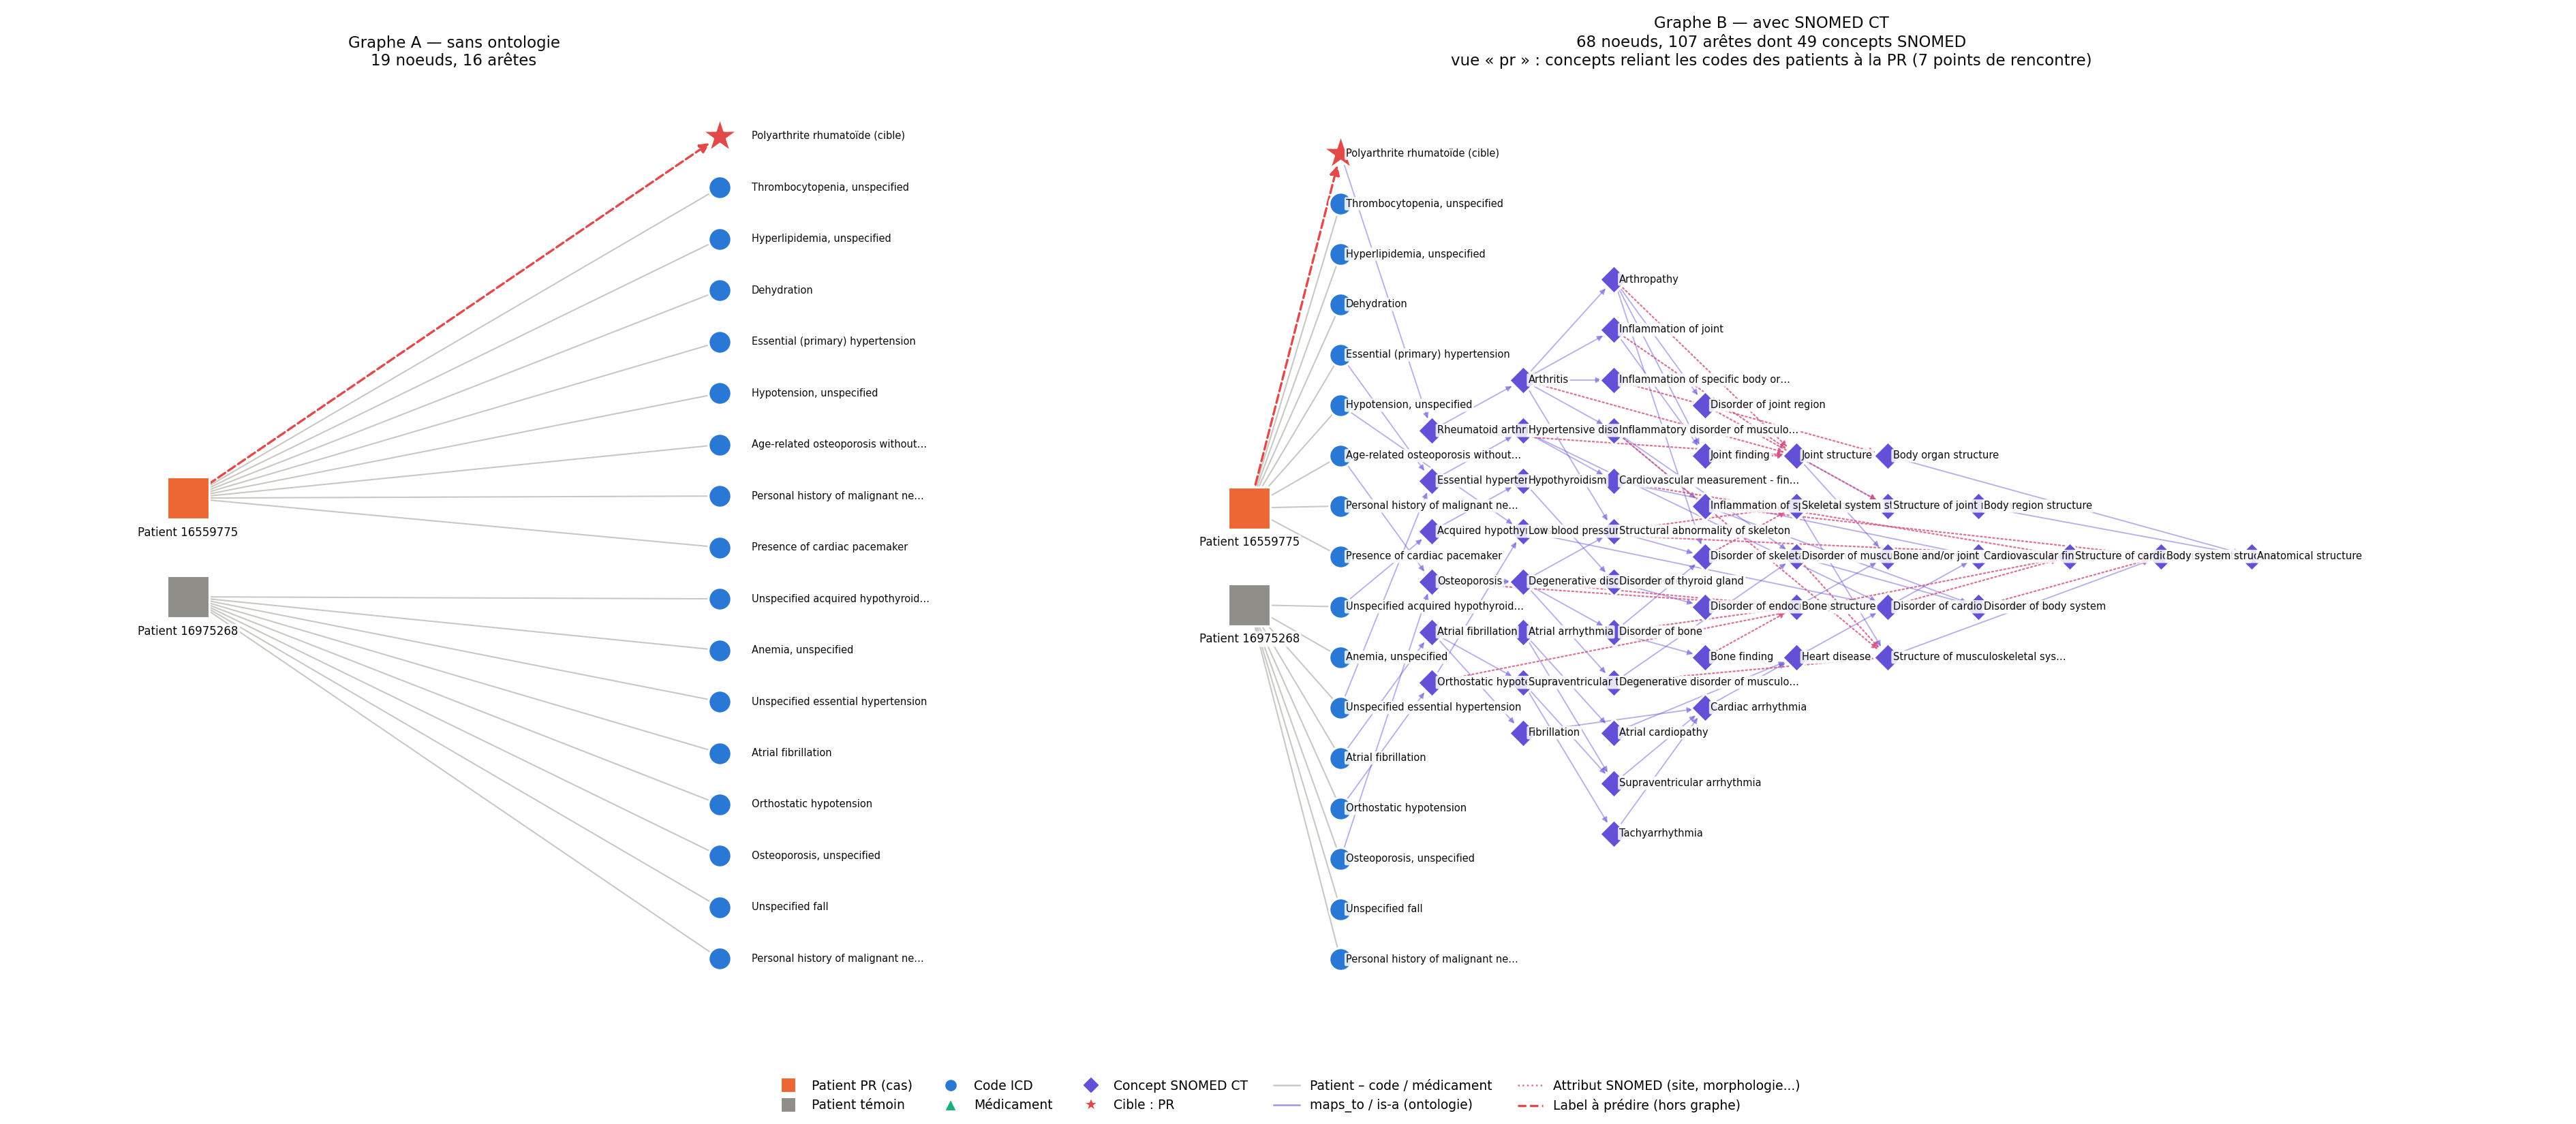

In [ ]:
!python /content/visualize_graphs.py --graphs-dir "{OUT}_test" --out /content/graphes_A_B.png

from IPython.display import Image, display
display(Image("/content/graphes_A_B.png"))

## 5. Cohorte complète

Ajoute `--pyg` pour obtenir aussi les fichiers PyTorch Geometric (installe d'abord `torch_geometric`).

In [ ]:
!python /content/build_graphs.py --mimic-dir "{MIMIC}" --athena-dir "{ATHENA}" \
    --out-dir "{OUT}" --graphml --no-drugs

Lecture de MIMIC-IV...
  cohorte : 837 cas PR, 4185 témoins
Graphe A : {'nodes': {'patient': 5022, 'icd': 3261, 'outcome': 1}, 'edges': {'has_diagnosis': 112141}}
Lecture de SNOMED CT et du mapping ICD -> SNOMED...
  vocabulaires trouvés dans CONCEPT.csv : {'SNOMED': 1106309, 'ICD10CM': 100273, 'ICD9CM': 17564}
  sens retenu pour les relations à double sens : After (et non « Before »); Characterizes (et non « Is characterized by »); During (et non « Has complication »); Finding asso with (et non « Asso with finding »); Followed by (et non « Follows »); Has absorbability (et non « Absorbability of »); Has access (et non « Access of »); Has active ing (et non « Active ing of »); Has admin method (et non « Admin method of »); Has approach (et non « Approach of »); Has asso finding (et non « Asso finding of »); Has asso morph (et non « Asso morph of »); Has asso proc (et non « Asso proc of »); Has basic dose form (et non « Basic dose form of »); Has basis str subst (et non « Basis str subs

# Étapes 3 et 4 : export PyTorch Geometric et entraînement du GNN sur A et B

À lancer dans le même dossier de résultats que le notebook principal. Pour aller plus vite : Exécution → Modifier le type d'exécution → GPU.


In [ ]:
BASE   = "/content/drive/MyDrive/Youssef/StageLirmm"
MIMIC  = BASE + "/hosp"
ATHENA = BASE + "/vocabulary_download_v5_{fa4cccb1-e82c-4ae5-bc68-563863e183ee}_1791532254461"
OUT    = BASE + "/graphs_out_test"      # BASE + "/graphs_out" pour la cohorte complète

In [ ]:
!pip install -q torch_geometric
import torch, torch_geometric
print('torch', torch.__version__, '| PyG', torch_geometric.__version__, '| GPU :', torch.cuda.is_available())

torch 2.11.0+cu130 | PyG 2.8.1 | GPU : True


Reconstruit les graphes avec `--pyg` (même commande que l'essai, avec `/content/build_graphs.py` écrit par le notebook principal). Si tu ouvres ce notebook dans une nouvelle session, relance d'abord la cellule `%%writefile /content/build_graphs.py` du notebook principal.

In [ ]:
!python /content/build_graphs.py --mimic-dir "{MIMIC}" --athena-dir "{ATHENA}" \
    --out-dir "{OUT}" --max-cases 200 --no-drugs --pyg

Lecture de MIMIC-IV...
  cohorte : 200 cas PR, 1000 témoins
Graphe A : {'nodes': {'icd': 1205, 'patient': 1200, 'outcome': 1}, 'edges': {'has_diagnosis': 22162}}
Lecture de SNOMED CT et du mapping ICD -> SNOMED...
  vocabulaires trouvés dans CONCEPT.csv : {'SNOMED': 1106309, 'ICD10CM': 100273, 'ICD9CM': 17564}
  sens retenu pour les relations à double sens : After (et non « Before »); Characterizes (et non « Is characterized by »); During (et non « Has complication »); Finding asso with (et non « Asso with finding »); Followed by (et non « Follows »); Has absorbability (et non « Absorbability of »); Has access (et non « Access of »); Has active ing (et non « Active ing of »); Has admin method (et non « Admin method of »); Has approach (et non « Approach of »); Has asso finding (et non « Asso finding of »); Has asso morph (et non « Asso morph of »); Has asso proc (et non « Asso proc of »); Has basic dose form (et non « Basic dose form of »); Has basis str subst (et non « Basis str subst

### Vérification de l'export

In [ ]:
for name in ['A', 'B']:
    data = torch.load(f'{OUT}/graph_{name}.pt', weights_only=False)
    y = data['patient'].y
    print(f'--- Graphe {name} : {int(y.sum())} cas PR / {len(y)} patients')
    for t in data.node_types:
        print(f'   noeuds {t:10s} {data[t].num_nodes}')
    for et in data.edge_types:
        print(f'   arêtes {str(et):60s} {data[et].num_edges}')
    data.validate()

--- Graphe A : 200 cas PR / 1200 patients
   noeuds patient    1200
   noeuds icd        1205
   noeuds outcome    1
   arêtes ('patient', 'has_diagnosis', 'icd')                          22162
   arêtes ('icd', 'rev_has_diagnosis', 'patient')                      22162
--- Graphe B : 200 cas PR / 1200 patients
   noeuds patient    1200
   noeuds icd        1205
   noeuds outcome    1
   noeuds snomed     4113
   arêtes ('icd', 'maps_to', 'snomed')                                 1191
   arêtes ('outcome', 'maps_to', 'snomed')                             1
   arêtes ('patient', 'has_diagnosis', 'icd')                          22162
   arêtes ('snomed', 'during', 'snomed')                               18
   arêtes ('snomed', 'finding_asso_with', 'snomed')                    74
   arêtes ('snomed', 'followed_by', 'snomed')                          114
   arêtes ('snomed', 'has_asso_finding', 'snomed')                     38
   arêtes ('snomed', 'has_asso_morph', 'snomed')               

/usr/local/lib/python3.13/dist-packages/torch_geometric/data/hetero_data.py:429: UserWarning: The node types {'outcome'} are isolated and are not referenced by any edge type 
  warn_or_raise(  # May be intended.


## 4. Entraîner le même GNN sur A et B et comparer

Même split de patients pour A et B (enregistré dans `splits.csv`), 5 seeds, seuil choisi sur la validation. Sur 200 cas, compte quelques minutes ; les résultats seront très incertains : c'est un test du pipeline, la vraie comparaison se fait sur la cohorte complète.

In [ ]:
%%writefile /content/train_gnn.py
"""
Entraîne le même GNN sur le graphe A (sans ontologie) et le graphe B (avec SNOMED CT),
puis compare précision, rappel, F1 (classe PR), AUPRC et AUROC.

Entrée : graph_A.pt et graph_B.pt produits par build_graphs.py --pyg.

Protocole (identique pour A et B)
  - Tâche : prédire si un patient a la PR (= le lien patient -> PR), classification des noeuds patients.
  - Split des PATIENTS stratifié 60 / 20 / 20, enregistré dans splits.csv et réutilisé à chaque lancement :
    A et B voient exactement les mêmes patients en train, validation et test.
    Tous les patients restent dans le graphe (apprentissage transductif) : seuls leurs labels sont cachés.
  - Features : âge et sexe pour les patients ; embedding appris pour les codes, médicaments et concepts.
  - Modèle : HeteroConv SAGE, un jeu de poids par type de relation (proche de R-GCN), ou HGT (--model hgt).
  - Perte pondérée (classe PR minoritaire), arrêt précoce sur l'AUPRC de validation.
  - Seuil de décision choisi sur la validation (F1 max), puis appliqué tel quel au test.
  - Plusieurs seeds ; comparaison finale par bootstrap apparié sur les mêmes patients de test.

Exemple
  python train_gnn.py --graphs-dir graphs_out_test --out-dir resultats_test
  python train_gnn.py --graphs-dir graphs_out --model hgt --seeds 5
"""

import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from torch_geometric.nn import HeteroConv, HGTConv, SAGEConv


# --------------------------------------------------------------------------------------
# Données
# --------------------------------------------------------------------------------------
def load_graph(path: Path):
    data = torch.load(path, weights_only=False)
    # Le noeud cible "PR" n'est relié à aucun patient : inutile pour classer les patients, on le retire
    for et in [et for et in data.edge_types if "outcome" in (et[0], et[2])]:
        del data[et]
    if "outcome" in data.node_types:
        del data["outcome"]
    return data


def make_splits(node_ids, y, path: Path, seed=0):
    """Split stratifié des patients, écrit une fois puis réutilisé (mêmes patients pour A et B)."""
    if path.exists():
        s = pd.read_csv(path, dtype={"node_id": str})
        if set(s["node_id"]) == set(node_ids):
            return s
        print(f"  {path.name} ne correspond plus aux patients du graphe : nouveau split")
    idx = np.arange(len(node_ids))
    train, rest = train_test_split(idx, test_size=0.4, stratify=y, random_state=seed)
    val, test = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=seed)
    split = np.empty(len(idx), dtype=object)
    split[train], split[val], split[test] = "train", "val", "test"
    s = pd.DataFrame({"node_id": node_ids, "y": y, "split": split})
    s.to_csv(path, index=False)
    return s


def masks(data, splits, device):
    pos = {n: i for i, n in enumerate(data["patient"].node_ids)}
    out = {}
    for name in ("train", "val", "test"):
        ids = splits.loc[splits["split"] == name, "node_id"].map(pos).values
        out[name] = torch.tensor(np.sort(ids), dtype=torch.long, device=device)
    return out


# --------------------------------------------------------------------------------------
# Modèle
# --------------------------------------------------------------------------------------
class HeteroGNN(nn.Module):
    def __init__(self, data, hidden=64, layers=2, model="sage", dropout=0.3):
        super().__init__()
        node_types, edge_types = data.metadata()
        self.dropout = dropout
        self.patient_in = nn.Linear(data["patient"].x.size(1), hidden)
        self.emb = nn.ModuleDict({t: nn.Embedding(data[t].num_nodes, hidden)
                                  for t in node_types if t != "patient"})
        self.convs = nn.ModuleList()
        for _ in range(layers):
            if model == "hgt":
                self.convs.append(HGTConv(hidden, hidden, data.metadata(), heads=2))
            else:
                self.convs.append(HeteroConv({et: SAGEConv((hidden, hidden), hidden) for et in edge_types},
                                             aggr="sum"))
        self.norms = nn.ModuleList([nn.ModuleDict({t: nn.LayerNorm(hidden) for t in node_types})
                                    for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
                                  nn.Linear(hidden, 1))

    def forward(self, data):
        x = {"patient": self.patient_in(data["patient"].x)}
        x.update({t: e.weight for t, e in self.emb.items()})
        for conv, norm in zip(self.convs, self.norms):
            out = conv(x, data.edge_index_dict)
            x = {t: norm[t](h + F.dropout(F.relu(out[t]), self.dropout, self.training))
                 if out.get(t) is not None else h for t, h in x.items()}
        return self.head(x["patient"]).squeeze(-1)


# --------------------------------------------------------------------------------------
# Métriques
# --------------------------------------------------------------------------------------
def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.argmax(f1[:-1])])


def metrics(y, p, t):
    yh = (p >= t).astype(int)
    return {"precision": precision_score(y, yh, zero_division=0), "recall": recall_score(y, yh),
            "f1": f1_score(y, yh), "auprc": average_precision_score(y, p), "auroc": roc_auc_score(y, p)}


def train_one(data, m, args, seed, device):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = HeteroGNN(data, args.hidden, args.layers, args.model, args.dropout).to(device)
    y = data["patient"].y.float()
    n_pos = y[m["train"]].sum()
    pos_weight = (len(m["train"]) - n_pos) / n_pos
    opt = torch.optim.Adam(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)

    best, best_state, wait = -1.0, None, 0
    for epoch in range(args.epochs):
        model.train()
        opt.zero_grad()
        logits = model(data)
        loss = F.binary_cross_entropy_with_logits(logits[m["train"]], y[m["train"]], pos_weight=pos_weight)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = torch.sigmoid(model(data))
        val = average_precision_score(y[m["val"]].cpu().numpy(), p[m["val"]].cpu().numpy())
        if val > best:
            best, wait = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= args.patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(data)).cpu().numpy()
    return p, epoch + 1, best


def paired_bootstrap(y, pa, pb, ta, tb, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    d_f1, d_ap = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0:
            continue
        d_f1.append(f1_score(y[i], pb[i] >= tb) - f1_score(y[i], pa[i] >= ta))
        d_ap.append(average_precision_score(y[i], pb[i]) - average_precision_score(y[i], pa[i]))
    ci = lambda d: (float(np.mean(d)), *np.percentile(d, [2.5, 97.5]).round(4).tolist())
    return {"delta_f1": ci(d_f1), "delta_auprc": ci(d_ap)}


# --------------------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--graphs-dir", default=Path("graphs_out"), type=Path)
    ap.add_argument("--out-dir", default=Path("resultats"), type=Path)
    ap.add_argument("--model", choices=["sage", "hgt"], default="sage")
    ap.add_argument("--hidden", type=int, default=64)
    ap.add_argument("--layers", type=int, default=2)
    ap.add_argument("--dropout", type=float, default=0.3)
    ap.add_argument("--lr", type=float, default=5e-3)
    ap.add_argument("--weight-decay", type=float, default=1e-5)
    ap.add_argument("--epochs", type=int, default=300)
    ap.add_argument("--patience", type=int, default=40)
    ap.add_argument("--seeds", type=int, default=5)
    args = ap.parse_args()
    args.out_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Appareil :", device)

    graphs = {}
    for name in ("A", "B"):
        path = args.graphs_dir / f"graph_{name}.pt"
        if not path.exists():
            raise SystemExit(f"{path} introuvable : relance build_graphs.py avec --pyg")
        graphs[name] = load_graph(path)
    ids = list(graphs["A"]["patient"].node_ids)
    if ids != list(graphs["B"]["patient"].node_ids):
        raise SystemExit("Les patients de A et B diffèrent : reconstruis les deux graphes ensemble.")

    y_all = graphs["A"]["patient"].y.numpy()
    splits = make_splits(ids, y_all, args.graphs_dir / "splits.csv")
    print("Split :", splits.groupby("split")["y"].agg(patients="size", cas_PR="sum").to_dict("index"))

    rows, preds = [], {}
    for name, data in graphs.items():
        nt, et = data.metadata()
        print(f"\nGraphe {name} : {len(nt)} types de noeuds, {len(et)} types d'arêtes, "
              f"{sum(data[t].num_nodes for t in nt)} noeuds, {sum(data[e].num_edges for e in et)} arêtes")
        data = data.to(device)
        m = masks(data, splits, device)
        y = data["patient"].y.cpu().numpy()
        probs = []
        for seed in range(args.seeds):
            p, n_ep, val_ap = train_one(data, m, args, seed, device)
            vi, ti = m["val"].cpu().numpy(), m["test"].cpu().numpy()
            t = best_threshold(y[vi], p[vi])
            r = {"graphe": name, "seed": seed, "epochs": n_ep, "seuil": t} | metrics(y[ti], p[ti], t)
            rows.append(r)
            probs.append(p)
            print(f"  seed {seed} : {n_ep} epochs, F1 test {r['f1']:.3f}, AUPRC test {r['auprc']:.3f}")
        preds[name] = np.mean(probs, axis=0)       # moyenne des seeds (ensemble)

    res = pd.DataFrame(rows)
    res.to_csv(args.out_dir / "resultats_par_seed.csv", index=False)
    cols = ["precision", "recall", "f1", "auprc", "auroc"]
    summary = res.groupby("graphe")[cols].agg(["mean", "std"]).round(3)
    print("\nMoyenne ± écart-type sur les seeds (test) :")
    print(summary.to_string())

    # Comparaison finale sur les probabilités moyennées, seuils choisis sur la validation
    vi = splits.index[splits["split"] == "val"].values
    ti = splits.index[splits["split"] == "test"].values
    pos = {n: i for i, n in enumerate(ids)}
    vi = np.array([pos[n] for n in splits.loc[vi, "node_id"]])
    ti = np.array([pos[n] for n in splits.loc[ti, "node_id"]])
    t = {k: best_threshold(y_all[vi], preds[k][vi]) for k in preds}
    final = {k: metrics(y_all[ti], preds[k][ti], t[k]) for k in preds}
    boot = paired_bootstrap(y_all[ti], preds["A"][ti], preds["B"][ti], t["A"], t["B"])

    print("\nEnsemble des seeds, test :")
    print(pd.DataFrame(final).T.round(3).to_string())
    for k, (mean, lo, hi) in boot.items():
        verdict = "écart significatif" if lo > 0 or hi < 0 else "pas d'écart significatif"
        print(f"{k.replace('delta_', 'Δ ').upper()} (B − A) : {mean:+.3f}  IC95% [{lo:+.3f} ; {hi:+.3f}]  → {verdict}")

    pd.DataFrame({"node_id": ids, "y": y_all, "split": splits.set_index("node_id").loc[ids, "split"].values,
                  "p_A": preds["A"], "p_B": preds["B"]}).to_csv(args.out_dir / "predictions.csv", index=False)
    (args.out_dir / "comparaison.json").write_text(json.dumps(
        {"config": {k: str(v) for k, v in vars(args).items()}, "seuils": t, "test": final, "bootstrap": boot},
        indent=2, ensure_ascii=False))
    print(f"\nRésultats dans {args.out_dir.resolve()}")


if __name__ == "__main__":
    main()


Writing /content/train_gnn.py


In [ ]:
!python /content/train_gnn.py --graphs-dir "{OUT}" --out-dir "{OUT}/resultats_sage"

Appareil : cuda
Split : {'test': {'patients': 240, 'cas_PR': 40}, 'train': {'patients': 720, 'cas_PR': 120}, 'val': {'patients': 240, 'cas_PR': 40}}

Graphe A : 2 types de noeuds, 2 types d'arêtes, 2405 noeuds, 44324 arêtes
  seed 0 : 46 epochs, F1 test 0.365, AUPRC test 0.287
  seed 1 : 48 epochs, F1 test 0.256, AUPRC test 0.280
  seed 2 : 45 epochs, F1 test 0.348, AUPRC test 0.271
  seed 3 : 45 epochs, F1 test 0.315, AUPRC test 0.300
  seed 4 : 44 epochs, F1 test 0.257, AUPRC test 0.302

Graphe B : 3 types de noeuds, 27 types d'arêtes, 6518 noeuds, 66954 arêtes
  seed 0 : 45 epochs, F1 test 0.247, AUPRC test 0.267
  seed 1 : 45 epochs, F1 test 0.286, AUPRC test 0.277
  seed 2 : 45 epochs, F1 test 0.333, AUPRC test 0.255
  seed 3 : 47 epochs, F1 test 0.323, AUPRC test 0.255
  seed 4 : 43 epochs, F1 test 0.270, AUPRC test 0.293

Moyenne ± écart-type sur les seeds (test) :
       precision        recall            f1         auprc         auroc       
            mean    std   mean    s

Variante avec le modèle HGT (attention par type de relation) :

In [ ]:
!python /content/train_gnn.py --graphs-dir "{OUT}" --out-dir "{OUT}/resultats_hgt" --model hgt

Appareil : cuda
Split : {'test': {'patients': 240, 'cas_PR': 40}, 'train': {'patients': 720, 'cas_PR': 120}, 'val': {'patients': 240, 'cas_PR': 40}}

Graphe A : 2 types de noeuds, 2 types d'arêtes, 2405 noeuds, 44324 arêtes
  seed 0 : 46 epochs, F1 test 0.341, AUPRC test 0.314
  seed 1 : 46 epochs, F1 test 0.304, AUPRC test 0.276
  seed 2 : 46 epochs, F1 test 0.270, AUPRC test 0.302
  seed 3 : 41 epochs, F1 test 0.290, AUPRC test 0.232
  seed 4 : 45 epochs, F1 test 0.345, AUPRC test 0.277

Graphe B : 3 types de noeuds, 27 types d'arêtes, 6518 noeuds, 66954 arêtes
  seed 0 : 54 epochs, F1 test 0.329, AUPRC test 0.330
  seed 1 : 46 epochs, F1 test 0.352, AUPRC test 0.299
  seed 2 : 70 epochs, F1 test 0.312, AUPRC test 0.249
  seed 3 : 45 epochs, F1 test 0.333, AUPRC test 0.311
  seed 4 : 46 epochs, F1 test 0.293, AUPRC test 0.292

Moyenne ± écart-type sur les seeds (test) :
       precision        recall            f1         auprc         auroc       
            mean    std   mean    s

In [ ]:
%%writefile /content/train_gnn.py
"""
Entraîne le même GNN sur le graphe A (sans ontologie) et le graphe B (avec SNOMED CT),
puis compare précision, rappel, F1 (classe PR), AUPRC et AUROC.

Entrée : graph_A.pt et graph_B.pt produits par build_graphs.py --pyg.

Protocole (identique pour A et B)
  - Tâche : prédire si un patient a la PR (= le lien patient -> PR), classification des noeuds patients.
  - Split des PATIENTS stratifié 60 / 20 / 20, enregistré dans splits.csv et réutilisé à chaque lancement :
    A et B voient exactement les mêmes patients en train, validation et test.
    Tous les patients restent dans le graphe (apprentissage transductif) : seuls leurs labels sont cachés.
  - Features : âge et sexe pour les patients ; embedding appris pour les codes, médicaments et concepts.
  - Modèle : HeteroConv SAGE, un jeu de poids par type de relation (proche de R-GCN), ou HGT (--model hgt).
  - --frequence : les messages sont pondérés par log(1 + nombre de séjours où le code apparaît)
    (couche GraphConv au lieu de SAGEConv ; les arêtes de l'ontologie ont toutes le même poids).
  - Perte pondérée (classe PR minoritaire), arrêt précoce sur l'AUPRC de validation.
  - Seuil de décision choisi sur la validation (F1 max), puis appliqué tel quel au test.
  - Plusieurs seeds ; comparaison finale par bootstrap apparié sur les mêmes patients de test.

Exemple
  python train_gnn.py --graphs-dir graphs_out_test --out-dir resultats_test
  python train_gnn.py --graphs-dir graphs_out --model hgt --seeds 5
"""

import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from torch_geometric.nn import GraphConv, HeteroConv, HGTConv, SAGEConv


# --------------------------------------------------------------------------------------
# Données
# --------------------------------------------------------------------------------------
def load_graph(path: Path):
    data = torch.load(path, weights_only=False)
    # Le noeud cible "PR" n'est relié à aucun patient : inutile pour classer les patients, on le retire
    for et in [et for et in data.edge_types if "outcome" in (et[0], et[2])]:
        del data[et]
    if "outcome" in data.node_types:
        del data["outcome"]
    return data


def make_splits(node_ids, y, path: Path, seed=0):
    """Split stratifié des patients, écrit une fois puis réutilisé (mêmes patients pour A et B)."""
    if path.exists():
        s = pd.read_csv(path, dtype={"node_id": str})
        if set(s["node_id"]) == set(node_ids):
            return s
        print(f"  {path.name} ne correspond plus aux patients du graphe : nouveau split")
    idx = np.arange(len(node_ids))
    train, rest = train_test_split(idx, test_size=0.4, stratify=y, random_state=seed)
    val, test = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=seed)
    split = np.empty(len(idx), dtype=object)
    split[train], split[val], split[test] = "train", "val", "test"
    s = pd.DataFrame({"node_id": node_ids, "y": y, "split": split})
    s.to_csv(path, index=False)
    return s


def masks(data, splits, device):
    pos = {n: i for i, n in enumerate(data["patient"].node_ids)}
    out = {}
    for name in ("train", "val", "test"):
        ids = splits.loc[splits["split"] == name, "node_id"].map(pos).values
        out[name] = torch.tensor(np.sort(ids), dtype=torch.long, device=device)
    return out


# --------------------------------------------------------------------------------------
# Modèle
# --------------------------------------------------------------------------------------
class HeteroGNN(nn.Module):
    def __init__(self, data, hidden=64, layers=2, model="sage", dropout=0.3, frequence=False):
        super().__init__()
        node_types, edge_types = data.metadata()
        self.dropout = dropout
        self.frequence = frequence
        self.patient_in = nn.Linear(data["patient"].x.size(1), hidden)
        self.emb = nn.ModuleDict({t: nn.Embedding(data[t].num_nodes, hidden)
                                  for t in node_types if t != "patient"})
        self.convs = nn.ModuleList()
        for _ in range(layers):
            if model == "hgt":
                self.convs.append(HGTConv(hidden, hidden, data.metadata(), heads=2))
            else:
                conv = (lambda: GraphConv((hidden, hidden), hidden, aggr="mean")) if frequence else \
                       (lambda: SAGEConv((hidden, hidden), hidden))
                self.convs.append(HeteroConv({et: conv() for et in edge_types},
                                             aggr="sum"))
        self.norms = nn.ModuleList([nn.ModuleDict({t: nn.LayerNorm(hidden) for t in node_types})
                                    for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
                                  nn.Linear(hidden, 1))

    @staticmethod
    def weights(data):
        # Nombre de séjours -> log(1 + n) : 1 séjour = 0,69 ; 5 séjours = 1,79 ; 20 séjours = 3,04
        out = {}
        for et in data.edge_types:
            w = getattr(data[et], "edge_weight", None)
            out[et] = torch.log1p(w) if w is not None else \
                torch.full((data[et].num_edges,), float(np.log(2)), device=data[et].edge_index.device)
        return out

    def forward(self, data):
        x = {"patient": self.patient_in(data["patient"].x)}
        x.update({t: e.weight for t, e in self.emb.items()})
        for conv, norm in zip(self.convs, self.norms):
            if self.frequence:
                out = conv(x, data.edge_index_dict, edge_weight_dict=self.weights(data))
            else:
                out = conv(x, data.edge_index_dict)
            x = {t: norm[t](h + F.dropout(F.relu(out[t]), self.dropout, self.training))
                 if out.get(t) is not None else h for t, h in x.items()}
        return self.head(x["patient"]).squeeze(-1)


# --------------------------------------------------------------------------------------
# Métriques
# --------------------------------------------------------------------------------------
def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.argmax(f1[:-1])])


def metrics(y, p, t):
    yh = (p >= t).astype(int)
    return {"precision": precision_score(y, yh, zero_division=0), "recall": recall_score(y, yh),
            "f1": f1_score(y, yh), "auprc": average_precision_score(y, p), "auroc": roc_auc_score(y, p)}


def train_one(data, m, args, seed, device):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = HeteroGNN(data, args.hidden, args.layers, args.model, args.dropout, args.frequence).to(device)
    y = data["patient"].y.float()
    n_pos = y[m["train"]].sum()
    pos_weight = (len(m["train"]) - n_pos) / n_pos
    opt = torch.optim.Adam(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)

    best, best_state, wait = -1.0, None, 0
    for epoch in range(args.epochs):
        model.train()
        opt.zero_grad()
        logits = model(data)
        loss = F.binary_cross_entropy_with_logits(logits[m["train"]], y[m["train"]], pos_weight=pos_weight)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = torch.sigmoid(model(data))
        val = average_precision_score(y[m["val"]].cpu().numpy(), p[m["val"]].cpu().numpy())
        if val > best:
            best, wait = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= args.patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(data)).cpu().numpy()
    return p, epoch + 1, best


def paired_bootstrap(y, pa, pb, ta, tb, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    d_f1, d_ap = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0:
            continue
        d_f1.append(f1_score(y[i], pb[i] >= tb) - f1_score(y[i], pa[i] >= ta))
        d_ap.append(average_precision_score(y[i], pb[i]) - average_precision_score(y[i], pa[i]))
    ci = lambda d: (float(np.mean(d)), *np.percentile(d, [2.5, 97.5]).round(4).tolist())
    return {"delta_f1": ci(d_f1), "delta_auprc": ci(d_ap)}


# --------------------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--graphs-dir", default=Path("graphs_out"), type=Path)
    ap.add_argument("--out-dir", default=Path("resultats"), type=Path)
    ap.add_argument("--model", choices=["sage", "hgt"], default="sage")
    ap.add_argument("--hidden", type=int, default=64)
    ap.add_argument("--layers", type=int, default=2)
    ap.add_argument("--dropout", type=float, default=0.3)
    ap.add_argument("--lr", type=float, default=5e-3)
    ap.add_argument("--weight-decay", type=float, default=1e-5)
    ap.add_argument("--epochs", type=int, default=300)
    ap.add_argument("--patience", type=int, default=40)
    ap.add_argument("--seeds", type=int, default=5)
    ap.add_argument("--frequence", action="store_true",
                    help="pondérer les messages par le nombre de séjours (modèle sage seulement)")
    args = ap.parse_args()
    if args.frequence and args.model == "hgt":
        raise SystemExit("--frequence n'est disponible qu'avec --model sage (HGT ne lit pas les poids d'arêtes)")
    args.out_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Appareil :", device)

    graphs = {}
    for name in ("A", "B"):
        path = args.graphs_dir / f"graph_{name}.pt"
        if not path.exists():
            raise SystemExit(f"{path} introuvable : relance build_graphs.py avec --pyg")
        graphs[name] = load_graph(path)
    ids = list(graphs["A"]["patient"].node_ids)
    if ids != list(graphs["B"]["patient"].node_ids):
        raise SystemExit("Les patients de A et B diffèrent : reconstruis les deux graphes ensemble.")

    y_all = graphs["A"]["patient"].y.numpy()
    splits = make_splits(ids, y_all, args.graphs_dir / "splits.csv")
    print("Split :", splits.groupby("split")["y"].agg(patients="size", cas_PR="sum").to_dict("index"))

    rows, preds = [], {}
    for name, data in graphs.items():
        nt, et = data.metadata()
        print(f"\nGraphe {name} : {len(nt)} types de noeuds, {len(et)} types d'arêtes, "
              f"{sum(data[t].num_nodes for t in nt)} noeuds, {sum(data[e].num_edges for e in et)} arêtes")
        data = data.to(device)
        m = masks(data, splits, device)
        y = data["patient"].y.cpu().numpy()
        probs = []
        for seed in range(args.seeds):
            p, n_ep, val_ap = train_one(data, m, args, seed, device)
            vi, ti = m["val"].cpu().numpy(), m["test"].cpu().numpy()
            t = best_threshold(y[vi], p[vi])
            r = {"graphe": name, "seed": seed, "epochs": n_ep, "seuil": t} | metrics(y[ti], p[ti], t)
            rows.append(r)
            probs.append(p)
            print(f"  seed {seed} : {n_ep} epochs, F1 test {r['f1']:.3f}, AUPRC test {r['auprc']:.3f}")
        preds[name] = np.mean(probs, axis=0)       # moyenne des seeds (ensemble)

    res = pd.DataFrame(rows)
    res.to_csv(args.out_dir / "resultats_par_seed.csv", index=False)
    cols = ["precision", "recall", "f1", "auprc", "auroc"]
    summary = res.groupby("graphe")[cols].agg(["mean", "std"]).round(3)
    print("\nMoyenne ± écart-type sur les seeds (test) :")
    print(summary.to_string())

    # Comparaison finale sur les probabilités moyennées, seuils choisis sur la validation
    vi = splits.index[splits["split"] == "val"].values
    ti = splits.index[splits["split"] == "test"].values
    pos = {n: i for i, n in enumerate(ids)}
    vi = np.array([pos[n] for n in splits.loc[vi, "node_id"]])
    ti = np.array([pos[n] for n in splits.loc[ti, "node_id"]])
    t = {k: best_threshold(y_all[vi], preds[k][vi]) for k in preds}
    final = {k: metrics(y_all[ti], preds[k][ti], t[k]) for k in preds}
    boot = paired_bootstrap(y_all[ti], preds["A"][ti], preds["B"][ti], t["A"], t["B"])

    print("\nEnsemble des seeds, test :")
    print(pd.DataFrame(final).T.round(3).to_string())
    for k, (mean, lo, hi) in boot.items():
        verdict = "écart significatif" if lo > 0 or hi < 0 else "pas d'écart significatif"
        print(f"{k.replace('delta_', 'Δ ').upper()} (B − A) : {mean:+.3f}  IC95% [{lo:+.3f} ; {hi:+.3f}]  → {verdict}")

    pd.DataFrame({"node_id": ids, "y": y_all, "split": splits.set_index("node_id").loc[ids, "split"].values,
                  "p_A": preds["A"], "p_B": preds["B"]}).to_csv(args.out_dir / "predictions.csv", index=False)
    (args.out_dir / "comparaison.json").write_text(json.dumps(
        {"config": {k: str(v) for k, v in vars(args).items()}, "seuils": t, "test": final, "bootstrap": boot},
        indent=2, ensure_ascii=False))
    print(f"\nRésultats dans {args.out_dir.resolve()}")


if __name__ == "__main__":
    main()


Overwriting /content/train_gnn.py


In [ ]:
   !python /content/train_gnn.py --graphs-dir "{OUT}" --out-dir "{OUT}/resultats_sage_freq" --frequence

Appareil : cuda
Split : {'test': {'patients': 240, 'cas_PR': 40}, 'train': {'patients': 720, 'cas_PR': 120}, 'val': {'patients': 240, 'cas_PR': 40}}

Graphe A : 2 types de noeuds, 2 types d'arêtes, 2405 noeuds, 44324 arêtes
  seed 0 : 54 epochs, F1 test 0.382, AUPRC test 0.374
  seed 1 : 46 epochs, F1 test 0.293, AUPRC test 0.275
  seed 2 : 45 epochs, F1 test 0.286, AUPRC test 0.288
  seed 3 : 46 epochs, F1 test 0.348, AUPRC test 0.279
  seed 4 : 44 epochs, F1 test 0.291, AUPRC test 0.315

Graphe B : 3 types de noeuds, 27 types d'arêtes, 6518 noeuds, 66954 arêtes
  seed 0 : 55 epochs, F1 test 0.306, AUPRC test 0.345
  seed 1 : 45 epochs, F1 test 0.327, AUPRC test 0.301
  seed 2 : 45 epochs, F1 test 0.331, AUPRC test 0.250
  seed 3 : 47 epochs, F1 test 0.353, AUPRC test 0.260
  seed 4 : 43 epochs, F1 test 0.270, AUPRC test 0.300

Moyenne ± écart-type sur les seeds (test) :
       precision        recall            f1         auprc         auroc       
            mean    std   mean    s